# Brain Tumor MRI Image Classification

**Internship Project | Deep Learning | TensorFlow/Keras**

This notebook adapts the team's generic ML submission template to the assigned brain MRI image-classification problem. It includes dataset inspection, image preprocessing, a custom CNN, transfer learning, evaluation, model saving, and a single-image prediction example.

**Important:** The dataset was not included with the project PDF or notebook at the time this notebook was prepared. Therefore, no dataset counts, class names, model metrics, or results are fabricated. Run the notebook with the real dataset and use the generated outputs in the final report.

**Medical-use limitation:** This is an educational prototype, not a clinically validated diagnostic tool. Its predictions must not replace review by a qualified medical professional.


## 1. Project summary and problem statement

The goal is to train a deep-learning image classifier that predicts the dataset label for an uploaded brain MRI image. The required work includes:

- Inspecting the dataset and its class distribution.
- Preprocessing images and applying carefully chosen augmentation.
- Training a custom convolutional neural network (CNN).
- Training a transfer-learning model and comparing it with the custom CNN.
- Evaluating performance using accuracy, precision, recall, F1-score, and a confusion matrix.
- Saving the trained models and preparing them for a Streamlit application.

The exact number and names of classes will be taken from the supplied dataset, not assumed in advance.


## Dataset-specific notes

The uploaded archive contains the `Tumour/` folder with predefined `train/`, `valid/`, and `test/` splits and four labels: `glioma`, `meningioma`, `no_tumor`, and `pituitary`. The notebook detects `valid` as the validation split. Keep the original test split untouched until final evaluation.

The archive README states a CC BY 4.0 license and attributes the dataset to a Roboflow user. Review and retain the attribution/license terms if you redistribute the dataset or derived materials.


## 2. Setup and configuration

Install only the packages that are missing in your environment. In Google Colab, select **Runtime → Change runtime type → GPU** if a GPU is available. On a local system, set `DATA_DIR` below to the extracted dataset folder.

Supported common layouts:

1. `DATA_DIR/class_name/image.jpg`
2. `DATA_DIR/train/class_name/image.jpg` and optionally `DATA_DIR/test/class_name/image.jpg`
3. `DATA_DIR/train/...`, `DATA_DIR/val/...`, `DATA_DIR/test/...`

If your dataset uses a CSV file for labels or a different directory layout, inspect the structure in Section 3 and adjust the loader before training.

### Uploaded dataset checked

The uploaded ZIP contains the folder-based layout `Tumour/train`, `Tumour/valid`, and `Tumour/test`, with four class folders in each split. The dataset's own README describes 2,443 total images (1,695 train, 502 validation, 246 test). The file-level scan found these image counts:

| Split      |  Glioma | Meningioma | No tumor | Pituitary |     Total |
| ---------- | ------: | ---------: | -------: | --------: | --------: |
| Train      |     564 |        358 |      335 |       438 |     1,695 |
| Validation |     161 |        124 |       99 |       118 |       502 |
| Test       |      80 |         63 |       49 |        54 |       246 |
| **Total**  | **805** |    **545** |  **483** |   **610** | **2,443** |

These are file counts from the uploaded ZIP, not model results. The notebook uses the existing validation and test folders and should not split them again. If your extraction folder has a different path, update `DATA_DIR`.


In [2]:
%pip install numpy pandas matplotlib seaborn scikit-learn pillow tensorflow

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

NumPy: 2.5.3
Pandas: 3.0.6
TensorFlow: 2.22.0-rc0
GPU: []


In [4]:
# If required, uncomment and run in a fresh environment:
# %pip install -q tensorflow scikit-learn matplotlib seaborn pillow pandas

import os
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_recall_fscore_support
)
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python/TensorFlow environment ready")
print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

# CHANGE THIS to the folder that contains the extracted dataset.
# Example Windows: r"D:\Datasets\BrainTumorMRI"
# Example Colab:   "/content/Tumour"
DATA_DIR = Path(r"./Tumour")

# Training configuration; adjust after inspecting the dataset and hardware.
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS_CNN = 20
EPOCHS_TRANSFER = 10
VALIDATION_SPLIT = 0.20
TEST_SPLIT = 0.15
AUTOTUNE = tf.data.AUTOTUNE

# Artifacts are saved here. Change this if desired.
OUTPUT_DIR = Path("./artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

Python/TensorFlow environment ready
TensorFlow: 2.22.0-rc0
Available GPUs: []


## 3. Dataset inspection

Run this section first. It lists folders and counts image files without assuming the class names. The printed counts are the actual counts found on your machine.


In [5]:
if not DATA_DIR.exists():
    print(f"Dataset folder not found: {DATA_DIR.resolve()}")
    print("Update DATA_DIR to the extracted dataset folder, then rerun this cell.")
else:
    print("Dataset root:", DATA_DIR.resolve())
    for item in sorted(DATA_DIR.iterdir()):
        if item.is_dir():
            files = [p for p in item.rglob("*") if p.is_file()]
            print(f"{item.name:30s} {len(files):6d} files")
        else:
            print("File:", item.name)

Dataset root: C:\Users\rtktr\Desktop\Brain_Tumor_MRI_Classification\Tumour
File: README.dataset.txt
test                              247 files
train                            1696 files
valid                             503 files


In [6]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}

def count_images(folder):
    return sum(
        1 for p in Path(folder).rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

if DATA_DIR.exists():
    print("Total supported image files:", count_images(DATA_DIR))
    print("\nTop-level folders:")
    for folder in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
        print(f"{folder.name}: {count_images(folder)} images")

Total supported image files: 2443

Top-level folders:
test: 246 images
train: 1695 images
valid: 502 images


### Dataset layout decision

The loader below supports the common folder-based layouts. It expects each class to have its own subfolder. If you see an extra wrapper folder, set `DATA_DIR` to the folder that directly contains `train`, `test`, or class folders.

For a dataset with predefined train/validation/test folders, we use those splits. If there is a training folder but no validation folder, validation data is carved from training data. If there is only one folder of class subfolders, the code creates train/validation/test splits from that folder.

**Data-leakage caution:** If the dataset contains patient IDs or multiple scans from the same patient, a patient-level split is preferable. Folder-based random splits cannot guarantee patient-level separation.


In [7]:
def list_class_dirs(folder):
    folder = Path(folder)
    return sorted(
        p for p in folder.iterdir()
        if p.is_dir() and count_images(p) > 0
    )

def looks_like_class_root(folder):
    return len(list_class_dirs(folder)) >= 2

def find_dataset_layout(root):
    root = Path(root)
    if not root.exists():
        raise FileNotFoundError(
            f"DATA_DIR does not exist: {root.resolve()}. Update DATA_DIR first."
        )

    # Detect a common extra wrapper directory.
    candidates = [root] + sorted(p for p in root.iterdir() if p.is_dir())
    for candidate in candidates:
        child_names = {p.name.lower() for p in candidate.iterdir() if p.is_dir()}
        train_name = next((n for n in child_names if n in {"train", "training"}), None)
        val_name = next((n for n in child_names if n in {"val", "valid", "validation"}), None)
        test_name = next((n for n in child_names if n in {"test", "testing"}), None)

        if train_name:
            mapping = {p.name.lower(): p for p in candidate.iterdir() if p.is_dir()}
            train_dir = mapping[train_name]
            val_dir = mapping.get(val_name) if val_name else None
            test_dir = mapping.get(test_name) if test_name else None
            return {"root": candidate, "train": train_dir, "val": val_dir, "test": test_dir}

        if looks_like_class_root(candidate):
            return {"root": candidate, "train": candidate, "val": None, "test": None}

    raise ValueError(
        "Could not detect a folder-based dataset with class subfolders. "
        "Inspect DATA_DIR and adapt the loader if labels are stored in a CSV."
    )

layout = find_dataset_layout(DATA_DIR)
print("Detected root:", layout["root"].resolve())
print("Train/source folder:", layout["train"].resolve())
print("Validation folder:", layout["val"].resolve() if layout["val"] else "Will split from training data")
print("Test folder:", layout["test"].resolve() if layout["test"] else "Will split from training data")

Detected root: C:\Users\rtktr\Desktop\Brain_Tumor_MRI_Classification\Tumour
Train/source folder: C:\Users\rtktr\Desktop\Brain_Tumor_MRI_Classification\Tumour\train
Validation folder: C:\Users\rtktr\Desktop\Brain_Tumor_MRI_Classification\Tumour\valid
Test folder: C:\Users\rtktr\Desktop\Brain_Tumor_MRI_Classification\Tumour\test


## 4. Load image datasets

TensorFlow's directory loader derives labels from class-folder names. We keep a consistent class order across all splits and use a held-out test set only for final evaluation.

For the single-folder layout, training and validation are separated using a fixed seed. A test split is then taken from the remaining training data; for very small datasets, review the split sizes before training.


In [8]:
def make_directory_dataset(directory, class_names=None, validation_split=None, subset=None, shuffle=True):
    kwargs = dict(
        directory=str(directory),
        labels="inferred",
        label_mode="int",
        class_names=class_names,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        color_mode="rgb",
        seed=SEED,
        shuffle=shuffle
    )
    if validation_split is not None:
        kwargs["validation_split"] = validation_split
        kwargs["subset"] = subset
    return tf.keras.utils.image_dataset_from_directory(**kwargs)

if layout["val"] is None and layout["test"] is None:
    # One root containing class subfolders: make train and validation splits.
    train_ds = make_directory_dataset(
        layout["train"], validation_split=VALIDATION_SPLIT, subset="training"
    )
    val_ds = make_directory_dataset(
        layout["train"], class_names=train_ds.class_names,
        validation_split=VALIDATION_SPLIT, subset="validation", shuffle=False
    )
    class_names = train_ds.class_names
    # No untouched test folder exists. Reserve a test set from the original
    # dataset by using a separate validation_split is not supported directly
    # alongside the above split; use validation for development and report this
    # limitation, or create a separate train/val/test directory split offline.
    test_ds = None

elif layout["val"] is None and layout["test"] is not None:
    train_ds = make_directory_dataset(layout["train"])
    class_names = train_ds.class_names
    val_ds = make_directory_dataset(
        layout["train"], class_names=class_names,
        validation_split=VALIDATION_SPLIT, subset="validation", shuffle=False
    )
    # Recreate training subset consistently to avoid using validation images for training.
    train_ds = make_directory_dataset(
        layout["train"], class_names=class_names,
        validation_split=VALIDATION_SPLIT, subset="training"
    )
    test_ds = make_directory_dataset(layout["test"], class_names=class_names, shuffle=False)

else:
    train_ds = make_directory_dataset(layout["train"])
    class_names = train_ds.class_names
    if layout["val"] is not None:
        val_ds = make_directory_dataset(layout["val"], class_names=class_names, shuffle=False)
    else:
        val_ds = None
    test_ds = (
        make_directory_dataset(layout["test"], class_names=class_names, shuffle=False)
        if layout["test"] is not None else None
    )
    if val_ds is None:
        # Use a validation split from the training folder and keep the test folder untouched.
        val_ds = make_directory_dataset(
            layout["train"], class_names=class_names,
            validation_split=VALIDATION_SPLIT, subset="validation", shuffle=False
        )
        train_ds = make_directory_dataset(
            layout["train"], class_names=class_names,
            validation_split=VALIDATION_SPLIT, subset="training"
        )

NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)
print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy() if test_ds is not None else "No separate test set")

Found 1695 files belonging to 4 classes.
Found 502 files belonging to 4 classes.
Found 246 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Number of classes: 4
Train batches: 53
Validation batches: 16
Test batches: 8


## 5. Visualize sample images and class balance

The charts below are generated from the real data. Review them for mislabeled images, unexpected images, severe class imbalance, and unusual image content before training.


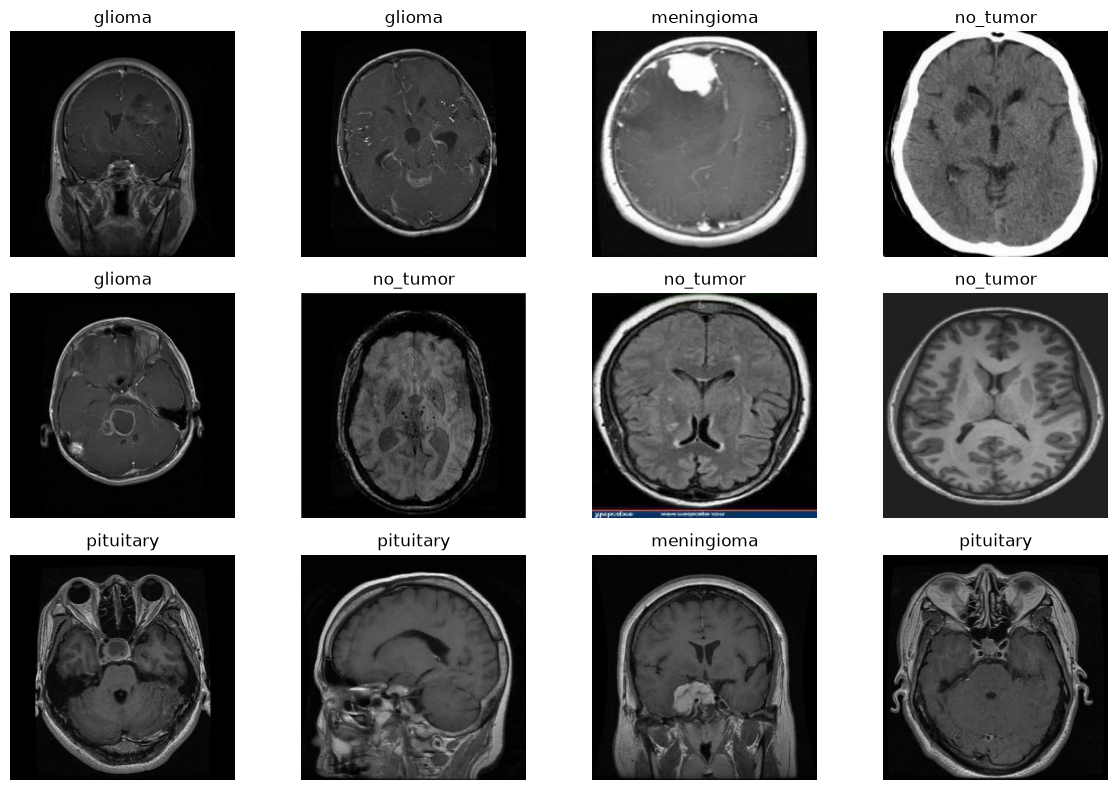

In [9]:
# Show a batch of training images.
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    n = min(12, len(images))
    for i in range(n):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
plt.tight_layout()
plt.show()

,class,image_count
0,glioma,564
1,meningioma,358
2,no_tumor,335
3,pituitary,438


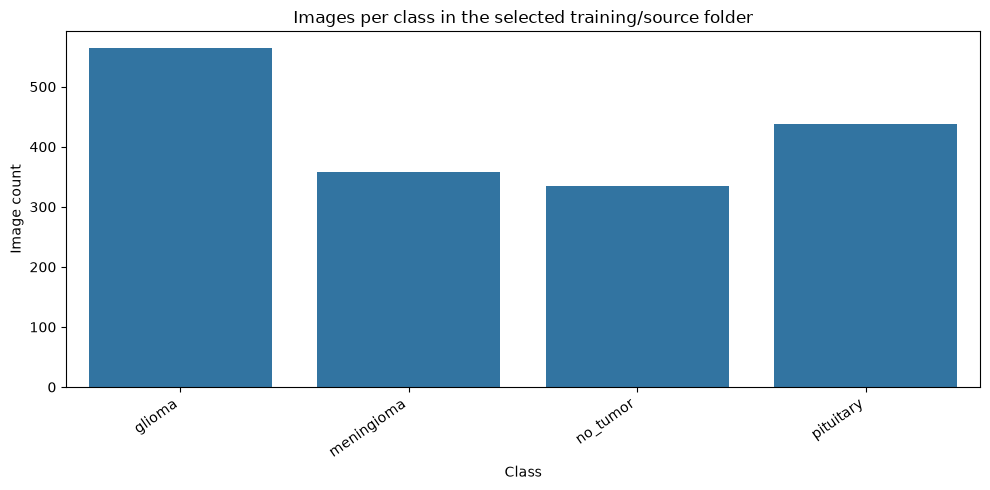

In [10]:
# Count images directly from class folders for a simple class-distribution plot.
source_root = layout["train"]
class_counts = {
    p.name: count_images(p)
    for p in list_class_dirs(source_root)
}
counts_df = pd.DataFrame(
    {"class": list(class_counts.keys()), "image_count": list(class_counts.values())}
).sort_values("class")

display(counts_df)
plt.figure(figsize=(10, 5))
sns.barplot(data=counts_df, x="class", y="image_count")
plt.title("Images per class in the selected training/source folder")
plt.xlabel("Class")
plt.ylabel("Image count")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Dataset observations (complete after running)

Record the actual class names, image counts, any class imbalance, image-quality issues, and any unexpected files here. Do not write conclusions until you have inspected the generated output.


## 6. Preprocessing and augmentation

Images are resized by the directory loader to `IMG_SIZE`. The augmentation layers are active only during training. Horizontal flipping and small rotations are common computer-vision augmentations, but for medical images each transformation should be checked for suitability. If the imaging protocol makes an augmentation clinically inappropriate, remove it.


In [11]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.04),
    tf.keras.layers.RandomZoom(0.08),
    tf.keras.layers.RandomTranslation(0.04, 0.04),
], name="data_augmentation")

def prepare_for_training(ds, training=False):
    ds = ds.cache()
    if training:
        ds = ds.shuffle(1000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = prepare_for_training(train_ds, training=True)
val_ds = prepare_for_training(val_ds)
if test_ds is not None:
    test_ds = prepare_for_training(test_ds)

## 7. Custom CNN model

The CNN is built from scratch with convolution, batch normalization, pooling, dropout, and a softmax output layer. The number of output units is based on the actual class count discovered from the dataset.


In [12]:
def build_custom_cnn(num_classes, input_shape=(*IMG_SIZE, 3)):
    inputs = tf.keras.Input(shape=input_shape)
    x = data_augmentation(inputs)
    x = tf.keras.layers.Rescaling(1.0 / 255)(x)

    for filters in [32, 64, 128]:
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.MaxPooling2D()(x)
        x = tf.keras.layers.Dropout(0.20)(x)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.35)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs, name="custom_brain_mri_cnn")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

cnn_model = build_custom_cnn(NUM_CLASSES)
cnn_model.summary()

Model: "custom_brain_mri_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 305,380 (1.16 MB)

 Trainable params: 304,484 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [14]:
cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(OUTPUT_DIR / "custom_cnn_best.keras"),
        monitor="val_loss", save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6, verbose=1
    )
]

start = time.time()
cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN,
    callbacks=cnn_callbacks
)
cnn_training_seconds = time.time() - start
print(f"Custom CNN training time: {cnn_training_seconds:.1f} seconds")

Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.7428 - loss: 0.6633
Epoch 1: val_loss improved from None to 3.41603, saving model to artifacts\custom_cnn_best.keras

Epoch 1: finished saving model to artifacts\custom_cnn_best.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 480s 9s/step - accuracy: 0.7428 - loss: 0.6633 - val_accuracy: 0.3267 - val_loss: 3.4160 - learning_rate: 0.0010
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7499 - loss: 0.6449
Epoch 2: val_loss improved from 3.41603 to 3.23515, saving model to artifacts\custom_cnn_best.keras

Epoch 2: finished saving model to artifacts\custom_cnn_best.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 253s 5s/step - accuracy: 0.7499 - loss: 0.6449 - val_accuracy: 0.2470 - val_loss: 3.2351 - learning_rate: 0.0010
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.7699 - loss: 0.5979
Epoch 3: val_loss improved from 3.23515 to 2.98892, saving model to artifacts\custom_cnn_best.keras

Epoch 3: finished saving model to artif

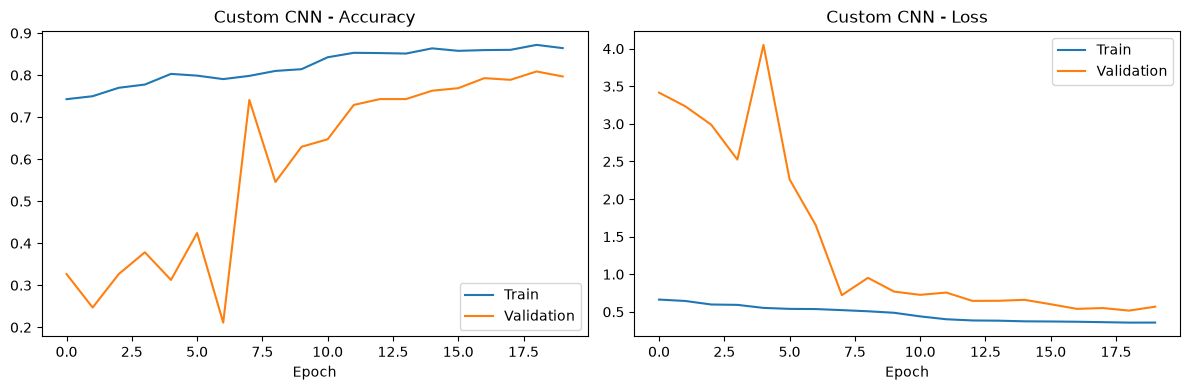

In [15]:
def plot_history(history, title):
    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist["accuracy"], label="Train")
    axes[0].plot(hist["val_accuracy"], label="Validation")
    axes[0].set_title(f"{title} - Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(hist["loss"], label="Train")
    axes[1].plot(hist["val_loss"], label="Validation")
    axes[1].set_title(f"{title} - Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(cnn_history, "Custom CNN")

## 8. Transfer learning with MobileNetV2

MobileNetV2 is used as the initial transfer-learning baseline because it is relatively lightweight. The pretrained ImageNet feature extractor is initially frozen; the new classification head is trained for the dataset's actual classes. Fine-tuning can be attempted later if validation performance and compute resources justify it.


In [16]:
# ImageNet pretrained weights require internet access the first time they are downloaded.
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
# MobileNetV2 preprocessing maps pixels from [0, 255] to [-1, 1].
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

transfer_model = tf.keras.Model(inputs, outputs, name="mobilenetv2_brain_mri")
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
transfer_model.summary()

Model: "mobilenetv2_brain_mri"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
transfer_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(OUTPUT_DIR / "mobilenetv2_best.keras"),
        monitor="val_loss", save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6, verbose=1
    )
]

start = time.time()
transfer_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_TRANSFER,
    callbacks=transfer_callbacks
)
transfer_training_seconds = time.time() - start
print(f"Transfer-learning training time: {transfer_training_seconds:.1f} seconds")

Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 602ms/step - accuracy: 0.7062 - loss: 0.7429
Epoch 1: val_loss improved from None to 0.64457, saving model to artifacts\mobilenetv2_best.keras

Epoch 1: finished saving model to artifacts\mobilenetv2_best.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 51s 879ms/step - accuracy: 0.7062 - loss: 0.7429 - val_accuracy: 0.7351 - val_loss: 0.6446 - learning_rate: 0.0010
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 634ms/step - accuracy: 0.8490 - loss: 0.4218
Epoch 2: val_loss improved from 0.64457 to 0.53582, saving model to artifacts\mobilenetv2_best.keras

Epoch 2: finished saving model to artifacts\mobilenetv2_best.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 48s 910ms/step - accuracy: 0.8490 - loss: 0.4218 - val_accuracy: 0.7948 - val_loss: 0.5358 - learning_rate: 0.0010
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 903ms/step - accuracy: 0.8755 - loss: 0.3573
Epoch 3: val_loss did not improve from 0.53582
53/53 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.8755 - loss: 0.3573 - 

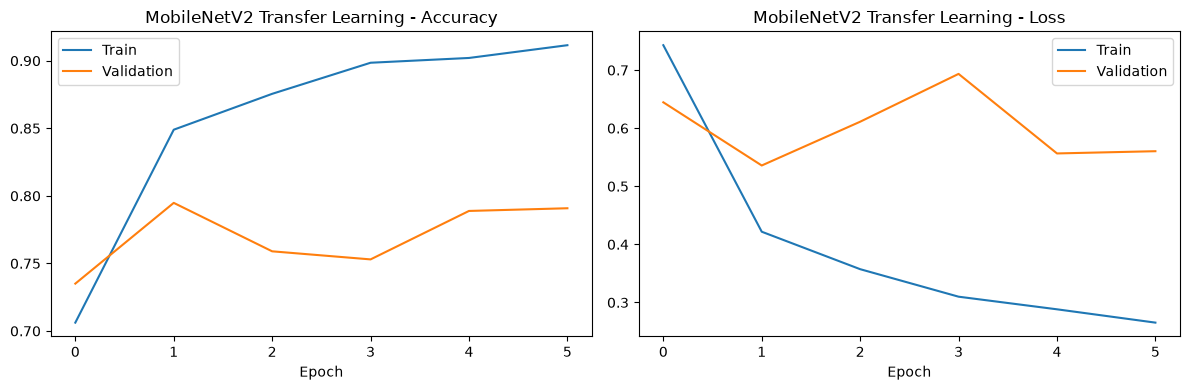

In [18]:
plot_history(transfer_history, "MobileNetV2 Transfer Learning")

### Optional fine-tuning

Only try fine-tuning after the frozen transfer-learning model has completed. Unfreeze a small number of top layers and use a low learning rate. Do not unfreeze all layers blindly; this can overfit or damage pretrained features, particularly on small datasets.


In [19]:
# Optional: uncomment to fine-tune the top layers after reviewing validation results.

base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
fine_tune_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=transfer_callbacks
)

Epoch 1/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8791 - loss: 0.3365
Epoch 1: val_loss did not improve from 0.53582
53/53 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.8791 - loss: 0.3365 - val_accuracy: 0.7610 - val_loss: 0.6478 - learning_rate: 1.0000e-05
Epoch 2/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8944 - loss: 0.2773
Epoch 2: val_loss did not improve from 0.53582
53/53 ━━━━━━━━━━━━━━━━━━━━ 118s 1s/step - accuracy: 0.8944 - loss: 0.2773 - val_accuracy: 0.7888 - val_loss: 0.5797 - learning_rate: 1.0000e-05
Epoch 3/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9204 - loss: 0.2260
Epoch 3: val_loss did not improve from 0.53582
53/53 ━━━━━━━━━━━━━━━━━━━━ 68s 1s/step - accuracy: 0.9204 - loss: 0.2260 - val_accuracy: 0.8088 - val_loss: 0.5461 - learning_rate: 1.0000e-05
Epoch 4/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9286 - loss: 0.1961
Epoch 4: val_loss did not improve from 0.53582
53/53 ━━━━━━━━━━━━━━━━━━━━ 74s 1s/step - accuracy: 0.9

## 9. Evaluation utilities

The final evaluation should use a held-out test set that was not used for model selection. If the dataset does not provide a test folder, create a separate train/validation/test split before treating results as final. The code below refuses to label validation performance as test performance.



Custom CNN
Accuracy:          0.8374
Weighted precision:0.8472
Weighted recall:   0.8374
Weighted F1-score: 0.8281

Classification report:
              precision    recall  f1-score   support

      glioma       0.96      0.95      0.96        80
  meningioma       0.85      0.52      0.65        63
    no_tumor       0.77      0.90      0.83        49
   pituitary       0.75      0.98      0.85        54

    accuracy                           0.84       246
   macro avg       0.83      0.84      0.82       246
weighted avg       0.85      0.84      0.83       246



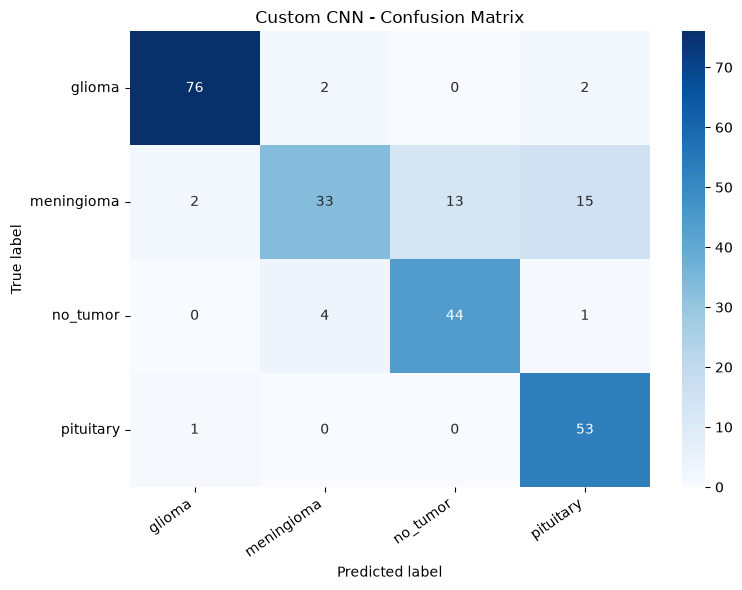


MobileNetV2
Accuracy:          0.8130
Weighted precision:0.8657
Weighted recall:   0.8130
Weighted F1-score: 0.8157

Classification report:
              precision    recall  f1-score   support

      glioma       0.96      0.88      0.92        80
  meningioma       0.95      0.59      0.73        63
    no_tumor       0.91      0.80      0.85        49
   pituitary       0.59      1.00      0.74        54

    accuracy                           0.81       246
   macro avg       0.85      0.81      0.81       246
weighted avg       0.87      0.81      0.82       246



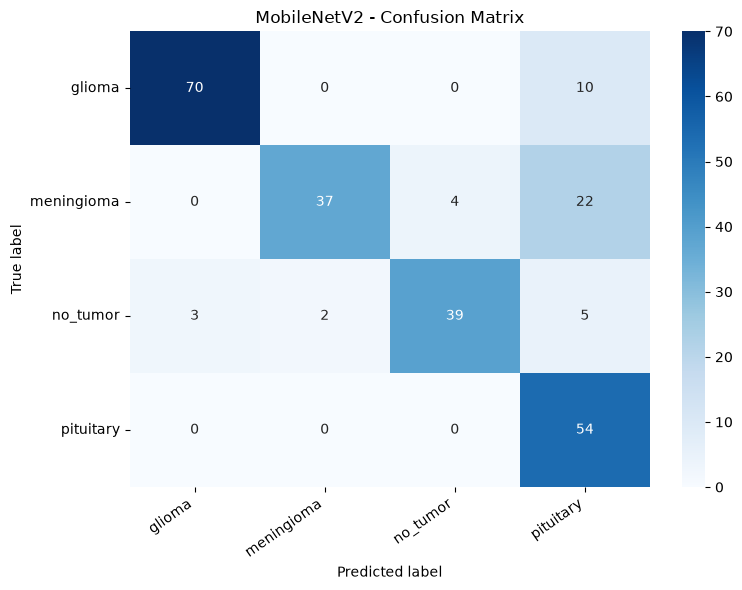

In [20]:
def collect_predictions(model, dataset):
    y_true, y_prob = [], []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        y_true.extend(labels.numpy().astype(int).tolist())
        y_prob.extend(probs.tolist())
    return np.array(y_true), np.array(y_prob)

def evaluate_model(model, dataset, model_name, labels):
    y_true, y_prob = collect_predictions(model, dataset)
    y_pred = np.argmax(y_prob, axis=1)

    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )

    print(f"\n{model_name}")
    print(f"Accuracy:          {accuracy:.4f}")
    print(f"Weighted precision:{precision:.4f}")
    print(f"Weighted recall:   {recall:.4f}")
    print(f"Weighted F1-score: {f1:.4f}")
    print("\nClassification report:")
    print(classification_report(
        y_true, y_pred, labels=list(range(len(labels))),
        target_names=labels, zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(labels))))
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=labels, yticklabels=labels
    )
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xticks(rotation=35, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return {
        "model": model_name,
        "accuracy": float(accuracy),
        "weighted_precision": float(precision),
        "weighted_recall": float(recall),
        "weighted_f1": float(f1)
    }

if test_ds is None:
    print(
        "No separate test dataset was detected. Do not report validation metrics as final test results. "
        "Create a dedicated test split before final evaluation."
    )
else:
    cnn_test_results = evaluate_model(cnn_model, test_ds, "Custom CNN", class_names)
    transfer_test_results = evaluate_model(transfer_model, test_ds, "MobileNetV2", class_names)

## 10. Model comparison

The table is populated only after the evaluation cell runs with a separate test set. Do not invent scores or choose a model based on training accuracy alone.


In [21]:
if test_ds is not None:
    comparison_df = pd.DataFrame([cnn_test_results, transfer_test_results])
    display(comparison_df.sort_values("weighted_f1", ascending=False))
else:
    print("Comparison table not generated: a separate test set is required.")

,model,accuracy,weighted_precision,weighted_recall,weighted_f1
0,Custom CNN,0.837398,0.847171,0.837398,0.828105
1,MobileNetV2,0.813008,0.865721,0.813008,0.815743


## 11. Save models and class labels

The project brief mentions `.h5` models. The native Keras `.keras` format is used for best checkpoints above. The following cell also exports `.h5` copies for compatibility with the brief. Keep the class-label JSON alongside the model because prediction indices must map to the same class names used during training.


In [22]:
class_mapping = {str(i): name for i, name in enumerate(class_names)}
with open(OUTPUT_DIR / "class_names.json", "w", encoding="utf-8") as f:
    json.dump(class_mapping, f, indent=2, ensure_ascii=False)

cnn_model.save(OUTPUT_DIR / "custom_cnn_final.keras")
transfer_model.save(OUTPUT_DIR / "mobilenetv2_final.keras")

# HDF5 exports requested by the project brief.
cnn_model.save(OUTPUT_DIR / "custom_cnn_final.h5")
transfer_model.save(OUTPUT_DIR / "mobilenetv2_final.h5")

print("Saved artifacts to:", OUTPUT_DIR.resolve())
print("Class mapping:", class_mapping)

Saved artifacts to: C:\Users\rtktr\Desktop\Brain_Tumor_MRI_Classification\artifacts
Class mapping: {'0': 'glioma', '1': 'meningioma', '2': 'no_tumor', '3': 'pituitary'}


## 12. Predict a single unseen MRI image

Set `IMAGE_PATH` to an image you want to test. Use the same preprocessing and model selected for deployment. The output score is a model score, not a medically calibrated probability or diagnosis.


In [23]:
from PIL import Image

IMAGE_PATH = ""  # Example: r"./example_mri.jpg"

def predict_one_image(image_path, model, labels, image_size=IMG_SIZE):
    image_path = Path(image_path)
    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path.resolve()}")

    image = tf.keras.utils.load_img(
        image_path, target_size=image_size, color_mode="rgb"
    )
    array = tf.keras.utils.img_to_array(image)
    batch = np.expand_dims(array, axis=0)

    probabilities = model.predict(batch, verbose=0)[0]
    best_index = int(np.argmax(probabilities))

    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Uploaded MRI image")
    plt.show()

    print("Predicted dataset label:", labels[best_index])
    print("Model score:", f"{probabilities[best_index] * 100:.2f}%")
    print("\nScores for all classes:")
    for label, score in zip(labels, probabilities):
        print(f"{label}: {score * 100:.2f}%")

    print("\nEducational use only; not a clinical diagnosis.")

# Uncomment after setting IMAGE_PATH:
# predict_one_image(IMAGE_PATH, transfer_model, class_names)

## 13. Streamlit deployment handoff

The app should load the selected saved model and `class_names.json`, accept an image upload, resize it to the expected input shape, display the predicted dataset class and model scores, and show a clear medical-use disclaimer. The app must use the same preprocessing as the selected model.

Suggested repository structure:

```text
brain-tumor-mri-classification/
├── notebooks/
│   └── Brain_Tumor_MRI_Classification.ipynb
├── app.py
├── artifacts/
│   ├── mobilenetv2_final.keras
│   └── class_names.json
├── requirements.txt
└── README.md
```

Do not commit a large dataset or private patient information to a public repository. Check the dataset's license and sharing terms before publishing any data or model artifacts.


## 14. Conclusion template (complete after running)

This project implemented a custom CNN and a MobileNetV2 transfer-learning classifier for the classes found in the Brain Tumor MRI dataset. The final report should state the actual dataset structure, split method, preprocessing, augmentation, training configuration, test-set metrics, confusion-matrix observations, limitations, and selected model. Fill in only values produced by the executed notebook.

The model is an educational prototype and must not be used as a substitute for professional medical interpretation.


## 15. Run checklist

- [ ] Set `DATA_DIR` to the real extracted dataset folder.
- [ ] Run setup and dataset inspection.
- [ ] Confirm class folders and class names.
- [ ] Review sample images and class distribution.
- [ ] Confirm that the train/validation/test split is appropriate.
- [ ] Train the custom CNN.
- [ ] Train MobileNetV2 transfer learning.
- [ ] Evaluate on an independent test set.
- [ ] Review class-wise recall and confusion matrix, not only accuracy.
- [ ] Save models and `class_names.json`.
- [ ] Test inference on unseen images.
- [ ] Build and test the Streamlit app.
- [ ] Complete README and GitHub repository.


In [24]:
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

ARTIFACT_DIR = Path("./artifacts")

best_path = ARTIFACT_DIR / "custom_cnn_best.keras"
final_path = ARTIFACT_DIR / "custom_cnn_final.keras"

print("Best model exists:", best_path.exists())
print("Final model exists:", final_path.exists())
print("Classes:", class_names)

Best model exists: True
Final model exists: True
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [25]:
def verify_saved_model(model_path, dataset):
    model = tf.keras.models.load_model(model_path)

    y_true = []
    y_pred = []

    for images, labels in dataset:
        probabilities = model.predict(images, verbose=0)

        y_true.extend(labels.numpy().astype(int))
        y_pred.extend(np.argmax(probabilities, axis=1))

    accuracy = accuracy_score(y_true, y_pred)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )

    return {
        "model": model_path.name,
        "accuracy": round(accuracy, 4),
        "weighted_precision": round(precision, 4),
        "weighted_recall": round(recall, 4),
        "weighted_f1": round(f1, 4)
    }


best_results = verify_saved_model(best_path, test_ds)
final_results = verify_saved_model(final_path, test_ds)

import pandas as pd

display(pd.DataFrame([best_results, final_results]))

,model,accuracy,weighted_precision,weighted_recall,weighted_f1
0,custom_cnn_best.keras,0.8374,0.8472,0.8374,0.8281
1,custom_cnn_final.keras,0.8374,0.8472,0.8374,0.8281


In [27]:
import numpy as np
import tensorflow as tf
from pathlib import Path

IMAGE_PATH = r"C:\Users\rtktr\Desktop\Brain_Tumor_MRI_Classification\Tumour\test\no_tumor\Tr-no_0022_jpg.rf.450e5c79c994c8f3ccfd6e41b45147b6.jpg"

model = tf.keras.models.load_model(
    "./artifacts/custom_cnn_best.keras"
)

image = tf.keras.utils.load_img(
    IMAGE_PATH,
    target_size=(224, 224),
    color_mode="rgb"
)

image_array = tf.keras.utils.img_to_array(image)
image_array = np.expand_dims(image_array, axis=0)

scores = model.predict(image_array, verbose=0)[0]
predicted_index = int(np.argmax(scores))

print("Predicted class:", class_names[predicted_index])

for name, score in zip(class_names, scores):
    print(f"{name}: {score * 100:.2f}%")

Predicted class: no_tumor
glioma: 0.12%
meningioma: 2.73%
no_tumor: 97.08%
pituitary: 0.08%
